# Métricas do Dashboard 2: impacto dos cancelamentos

Antes de levar os KPIs para o `app.py`, este notebook testa os cálculos e faz plots prévios (slide 15 da Aula 22).

- **Tema:** impacto dos cancelamentos nas reservas.
- **Público-alvo:** gerência de reservas e de receita do hotel.
- **Base:** `data/clean/dataset.csv`, exportado pelo `eda-com-downloads.ipynb`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

RAIZ = Path("..") if Path("../data").exists() else Path(".")
df = pd.read_csv(RAIZ / "data" / "clean" / "dataset.csv")

COR_NAO_CANCELADA = "#2A9D8F"
COR_CANCELADA = "#E76F51"

# Noites da estadia, usadas na receita perdida
df["noites"] = df["stays_in_week_nights"] + df["stays_in_weekend_nights"]
df["cancelada"] = df["status_reserva"].eq("Cancelada")
df.shape

(87229, 35)

## Métrica 1: taxa de cancelamento (`status_reserva`)

In [2]:
taxa_geral = df["cancelada"].mean()
print(f"Taxa de cancelamento geral: {taxa_geral:.1%}")
df.groupby("hotel")["cancelada"].mean().map("{:.1%}".format)

Taxa de cancelamento geral: 27.5%


hotel
City Hotel      30.1%
Resort Hotel    23.5%
Name: cancelada, dtype: object

## Métrica 2: receita perdida estimada (`adr` × noites das reservas canceladas)

In [3]:
receita = df["adr"] * df["noites"]
receita_perdida = receita[df["cancelada"]].sum()
receita_confirmada = receita[~df["cancelada"]].sum()

print(f"Receita perdida estimada: {receita_perdida:,.0f}")
print(f"Receita das reservas não canceladas: {receita_confirmada:,.0f}")
print(f"Perda sobre o total reservado: {receita_perdida / (receita_perdida + receita_confirmada):.1%}")

Receita perdida estimada: 11,484,043
Receita das reservas não canceladas: 22,967,612
Perda sobre o total reservado: 33.3%


O dataset não informa a moeda de `adr`, por isso os valores ficam sem símbolo. É uma **estimativa**: considera a tarifa média diária vezes as noites reservadas e ignora multas ou depósitos retidos.

## Métrica 3: antecedência mediana (`lead_time`), canceladas × não canceladas

In [4]:
df.groupby("status_reserva")["lead_time"].median()

status_reserva
Cancelada        80.0
Não cancelada    38.0
Name: lead_time, dtype: float64

## Métrica 4: tarifa média diária das reservas não canceladas (`adr`)

In [5]:
adr_medio = df.loc[~df["cancelada"], "adr"].mean()
print(f"Tarifa média diária (não canceladas): {adr_medio:.2f}")
df.loc[~df["cancelada"]].groupby("hotel")["adr"].mean().round(2)

Tarifa média diária (não canceladas): 102.22


hotel
City Hotel      108.64
Resort Hotel     93.00
Name: adr, dtype: float64

## Visual 1: taxa de cancelamento por faixa de antecedência

Agrupa `lead_time` em 5 faixas (slide 16: agrupar 1 variável e mostrar em barras).

,reservas,taxa
faixa_antecedencia,,
0–7 dias,18203,8.4%
8–30 dias,16326,25.4%
31–90 dias,22720,32.0%
91–180 dias,18224,35.0%
> 180 dias,11756,39.7%


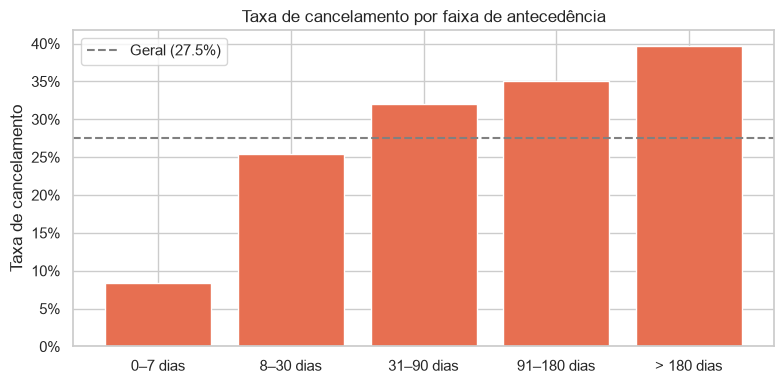

In [6]:
FAIXAS = [-1, 7, 30, 90, 180, np.inf]
ROTULOS = ["0–7 dias", "8–30 dias", "31–90 dias", "91–180 dias", "> 180 dias"]
df["faixa_antecedencia"] = pd.cut(df["lead_time"], bins=FAIXAS, labels=ROTULOS)

por_faixa = df.groupby("faixa_antecedencia", observed=True).agg(
    reservas=("cancelada", "size"), taxa=("cancelada", "mean")
)
display(por_faixa.style.format({"taxa": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(por_faixa.index.astype(str), por_faixa["taxa"], color=COR_CANCELADA)
ax.axhline(taxa_geral, color="gray", linestyle="--", label=f"Geral ({taxa_geral:.1%})")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylabel("Taxa de cancelamento")
ax.set_title("Taxa de cancelamento por faixa de antecedência")
ax.legend()
plt.tight_layout()
plt.show()

## Visual 2: taxa de cancelamento por mês de chegada

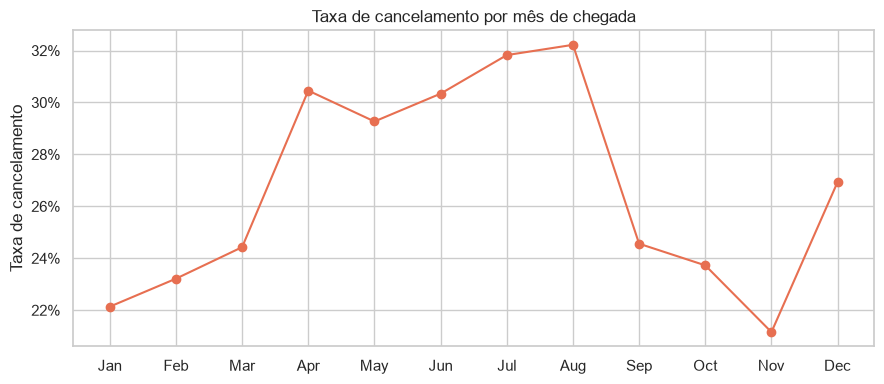

In [7]:
MESES = ["January", "February", "March", "April", "May", "June", "July",
         "August", "September", "October", "November", "December"]
por_mes = (
    df.groupby("arrival_date_month")["cancelada"].mean()
    .reindex(MESES)
)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(range(1, 13), por_mes.values, marker="o", color=COR_CANCELADA)
ax.set_xticks(range(1, 13), [m[:3] for m in MESES])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylabel("Taxa de cancelamento")
ax.set_title("Taxa de cancelamento por mês de chegada")
plt.tight_layout()
plt.show()

## Validação dos filtros do app

O app vai recalcular os KPIs com os filtros de hotel, ano e segmento de mercado. Aqui conferimos um recorte e o caso de filtro vazio.

In [8]:
def kpis(dados):
    if dados.empty:
        return None
    canc = dados["cancelada"]
    receita_dados = dados["adr"] * dados["noites"]
    return {
        "taxa_cancelamento": canc.mean(),
        "receita_perdida": receita_dados[canc].sum(),
        "lead_mediana_canceladas": dados.loc[canc, "lead_time"].median(),
        "lead_mediana_nao_canceladas": dados.loc[~canc, "lead_time"].median(),
        "adr_medio_nao_canceladas": dados.loc[~canc, "adr"].mean(),
    }


recorte = df[(df["hotel"] == "City Hotel") & (df["arrival_date_year"] == 2016)
             & (df["market_segment"] == "Online TA")]
print("City Hotel, 2016, Online TA:", kpis(recorte))
print("Filtro vazio:", kpis(df[df["market_segment"] == "Inexistente"]))

City Hotel, 2016, Online TA: {'taxa_cancelamento': np.float64(0.34923749719668085), 'receita_perdida': np.float64(2596506.37), 'lead_mediana_canceladas': np.float64(64.0), 'lead_mediana_nao_canceladas': np.float64(46.0), 'adr_medio_nao_canceladas': np.float64(114.80381493926077)}
Filtro vazio: None


**Atenção para o app:** em um recorte com só reservas canceladas (ou só não canceladas), a mediana e a média do outro grupo dão `NaN`. O app precisa mostrar "—" nesses casos.